In [32]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score

In [10]:
df = pd.read_csv('anime.csv')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (50, 3)


,Rank,Title,Score
0,1,Fullmetal Alchemist: BrotherhoodTV (64 eps)Apr...,9.10
1,2,"Steins;GateTV (24 eps)Apr 2011 - Sep 20112,473...",9.07
2,3,Bleach: Sennen Kessen-henTV (13 eps)Oct 2022 -...,9.06
3,4,"Gintama°TV (51 eps)Apr 2015 - Mar 2016605,113 ...",9.06
4,5,Shingeki no Kyojin Season 3 Part 2TV (10 eps)A...,9.05


In [11]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include='all'))


Column names:
['Rank', 'Title', 'Score']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Rank    50 non-null     int64  
 1   Title   50 non-null     str    
 2   Score   50 non-null     float64
dtypes: float64(1), int64(1), str(1)
memory usage: 5.3 KB

Statistical summary:


,Rank,Title,Score
count,50.00000,50,50.00000
unique,NaN,50,NaN
top,NaN,Fullmetal Alchemist: BrotherhoodTV (64 eps)Apr...,NaN
freq,NaN,1,NaN
mean,25.50000,NaN,8.88320
std,14.57738,NaN,0.11722
min,1.00000,NaN,8.71000
25%,13.25000,NaN,8.79000
50%,25.50000,NaN,8.85500
75%,37.75000,NaN,8.99000


In [14]:
def extract_episode(txt):
    check = False
    data = ""
    for i in txt:
        if i == ")":
            check = False
            break
        if check == True:
            data += i
        if i == '(':
            check = True
    return data
df['Episode'] = df["Title"].apply(extract_episode)
df['Episode'] = df['Episode'].str.replace('eps',"")
df['Episode'] = df['Episode'].astype(int)
df

,Rank,Title,Score,Episode
0,1,Fullmetal Alchemist: BrotherhoodTV (64 eps)Apr...,9.10,64
1,2,"Steins;GateTV (24 eps)Apr 2011 - Sep 20112,473...",9.07,24
2,3,Bleach: Sennen Kessen-henTV (13 eps)Oct 2022 -...,9.06,13
3,4,"Gintama°TV (51 eps)Apr 2015 - Mar 2016605,113 ...",9.06,51
4,5,Shingeki no Kyojin Season 3 Part 2TV (10 eps)A...,9.05,10
5,6,"Gintama'TV (51 eps)Apr 2011 - Mar 2012534,105 ...",9.04,51
6,7,Gintama: The FinalMovie (1 eps)Jan 2021 - Jan ...,9.04,1
7,8,Hunter x Hunter TV (148 eps)Oct 2011 - Sep 201...,9.04,148
8,9,Kaguya-sama wa Kokurasetai: Ultra RomanticTV (...,9.04,13
9,10,Gintama': EnchousenTV (13 eps)Oct 2012 - Mar 2...,9.03,13


In [16]:
def extract_time(txt):
    check = False
    data = ""
    for i in range(len(txt)):
        if txt[i] == ")":
            for j in range(i+1, i+20):
                data += txt[j]
    return data
df['Time Aired'] = df['Title'].apply(extract_time)
df

,Rank,Title,Score,Episode,Time Aired
0,1,Fullmetal Alchemist: BrotherhoodTV (64 eps)Apr...,9.10,64,Apr 2009 - Jul 2010
1,2,"Steins;GateTV (24 eps)Apr 2011 - Sep 20112,473...",9.07,24,Apr 2011 - Sep 2011
2,3,Bleach: Sennen Kessen-henTV (13 eps)Oct 2022 -...,9.06,13,Oct 2022 - Dec 2022
3,4,"Gintama°TV (51 eps)Apr 2015 - Mar 2016605,113 ...",9.06,51,Apr 2015 - Mar 2016
4,5,Shingeki no Kyojin Season 3 Part 2TV (10 eps)A...,9.05,10,Apr 2019 - Jul 2019
5,6,"Gintama'TV (51 eps)Apr 2011 - Mar 2012534,105 ...",9.04,51,Apr 2011 - Mar 2012
6,7,Gintama: The FinalMovie (1 eps)Jan 2021 - Jan ...,9.04,1,Jan 2021 - Jan 2021
7,8,Hunter x Hunter TV (148 eps)Oct 2011 - Sep 201...,9.04,148,Oct 2011 - Sep 2014
8,9,Kaguya-sama wa Kokurasetai: Ultra RomanticTV (...,9.04,13,Apr 2022 - Jun 2022
9,10,Gintama': EnchousenTV (13 eps)Oct 2012 - Mar 2...,9.03,13,Oct 2012 - Mar 2013


In [17]:
# Define a function to calculate the total months
def extract_months(time_aired):
    try:
        # Split the date range into start and end dates
        start_date, end_date = time_aired.split(' - ')

        # Convert the strings into datetime objects
        start_date = pd.to_datetime(start_date, format='%b %Y')
        end_date = pd.to_datetime(end_date, format='%b %Y')

        # Calculate the total months (inclusive)
        months = (
            (end_date.year - start_date.year) * 12
            + (end_date.month - start_date.month)
            + 1
        )

        return months

    except (ValueError, AttributeError):
        return None


# Apply the function to the Time Aired column
df['Months'] = df['Time Aired'].apply(extract_months)

# Display the results
df[['Time Aired', 'Months']].head(10)

,Time Aired,Months
0,Apr 2009 - Jul 2010,16
1,Apr 2011 - Sep 2011,6
2,Oct 2022 - Dec 2022,3
3,Apr 2015 - Mar 2016,12
4,Apr 2019 - Jul 2019,4
5,Apr 2011 - Mar 2012,12
6,Jan 2021 - Jan 2021,1
7,Oct 2011 - Sep 2014,36
8,Apr 2022 - Jun 2022,3
9,Oct 2012 - Mar 2013,6


In [18]:
df

,Rank,Title,Score,Episode,Time Aired,Months
0,1,Fullmetal Alchemist: BrotherhoodTV (64 eps)Apr...,9.10,64,Apr 2009 - Jul 2010,16
1,2,"Steins;GateTV (24 eps)Apr 2011 - Sep 20112,473...",9.07,24,Apr 2011 - Sep 2011,6
2,3,Bleach: Sennen Kessen-henTV (13 eps)Oct 2022 -...,9.06,13,Oct 2022 - Dec 2022,3
3,4,"Gintama°TV (51 eps)Apr 2015 - Mar 2016605,113 ...",9.06,51,Apr 2015 - Mar 2016,12
4,5,Shingeki no Kyojin Season 3 Part 2TV (10 eps)A...,9.05,10,Apr 2019 - Jul 2019,4
5,6,"Gintama'TV (51 eps)Apr 2011 - Mar 2012534,105 ...",9.04,51,Apr 2011 - Mar 2012,12
6,7,Gintama: The FinalMovie (1 eps)Jan 2021 - Jan ...,9.04,1,Jan 2021 - Jan 2021,1
7,8,Hunter x Hunter TV (148 eps)Oct 2011 - Sep 201...,9.04,148,Oct 2011 - Sep 2014,36
8,9,Kaguya-sama wa Kokurasetai: Ultra RomanticTV (...,9.04,13,Apr 2022 - Jun 2022,3
9,10,Gintama': EnchousenTV (13 eps)Oct 2012 - Mar 2...,9.03,13,Oct 2012 - Mar 2013,6


In [19]:
# Select the columns needed for our model
data = df[['Episode', 'Months', 'Score']].copy()

# Convert the columns to numeric values
for column in ['Episode', 'Months', 'Score']:
    data[column] = pd.to_numeric(
        data[column],
        errors='coerce'
    )

# Replace infinite values with missing values
data = data.replace([float('inf'), float('-inf')], float('nan'))

# Remove rows with missing values in the selected columns
data = data.dropna(subset=['Episode', 'Months', 'Score'])

# Display the cleaned data
display(data.head())

print("Usable records:", len(data))

,Episode,Months,Score
0,64,16,9.10
1,24,6,9.07
2,13,3,9.06
3,51,12,9.06
4,10,4,9.05


Usable records: 50


In [21]:
# Input features
X = data[['Episode', 'Months']]

# Target variable
y = data['Score']

print("Features:")
display(X.head())

print("Target:")
display(y.head())
# supervised learning.

Features:


,Episode,Months
0,64,16
1,24,6
2,13,3
3,51,12
4,10,4


Target:


0    9.10
1    9.07
2    9.06
3    9.06
4    9.05
Name: Score, dtype: float64

In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 40
Testing records: 10


**TRAINING MY FIRST MACHINE LEARNING MODEL!**

In [23]:
# Create the model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

print("My first ML model has been trained!")

My first ML model has been trained!


## Trained Linear Regression, a supervised machine learning algorithm used for regression problems.

**See what the model has learned**

In [24]:
print("Intercept:", model.intercept_)

print("\nFeature coefficients:")

for feature, coefficient in zip(X.columns, model.coef_):
    print(f"{feature}: {coefficient:.4f}")

Intercept: 8.873741058980345

Feature coefficients:
Episode: 0.0005
Months: 0.0006


**Linear Regression estimates an equation of this form:**
**Score = b + w1(Episode)+w2(Months)**

**Make predictions on the test data**

In [26]:
predictions = model.predict(X_test)

results = pd.DataFrame({
    'Actual Score': y_test.values,
    'Predicted Score': predictions
})

display(results)

,Actual Score,Predicted Score
0,8.99,8.882328
1,8.78,8.874896
2,8.82,8.886807
3,8.74,8.889891
4,8.93,8.888866
5,8.71,8.881816
6,8.84,8.874896
7,8.84,8.874896
8,8.81,8.899271
9,8.91,8.890403


**Evaluate the model**

In [33]:
mae = mean_absolute_error(y_test, predictions)

r2 = r2_score(y_test, predictions)

print("Mean Absolute Error:", round(mae, 3))
print("R² Score:", round(r2, 3))

Mean Absolute Error: 0.081
R² Score: -0.332


**Predict the score of a hypothetical anime**

In [34]:
new_anime = pd.DataFrame({
    'Episode': [24],
    'Months': [6]
})

predicted_score = model.predict(new_anime)

print(
    "Predicted Anime Score:",
    round(predicted_score[0], 2)
)

Predicted Anime Score: 8.89


In [35]:
# Compare actual and predicted scores
results = pd.DataFrame({
    'Actual Score': y_test,
    'Predicted Score': predictions
})

results['Absolute Error'] = (
    results['Actual Score'] - results['Predicted Score']
).abs()

display(results.round(3))

# Examine the variation in actual test scores
print("Actual score mean:", round(y_test.mean(), 3))
print("Actual score standard deviation:", round(y_test.std(), 3))

# Compare the model against a mean-prediction baseline
baseline_predictions = [y_train.mean()] * len(y_test)

baseline_mae = mean_absolute_error(
    y_test,
    baseline_predictions
)

baseline_r2 = r2_score(
    y_test,
    baseline_predictions
)

print("\nModel MAE:", round(mean_absolute_error(y_test, predictions), 3))
print("Baseline MAE:", round(baseline_mae, 3))

print("\nModel R²:", round(r2_score(y_test, predictions), 3))
print("Baseline R²:", round(baseline_r2, 3))

,Actual Score,Predicted Score,Absolute Error
13,8.99,8.882,0.108
39,8.78,8.875,0.095
30,8.82,8.887,0.067
45,8.74,8.890,0.150
17,8.93,8.889,0.041
48,8.71,8.882,0.172
26,8.84,8.875,0.035
25,8.84,8.875,0.035
32,8.81,8.899,0.089
19,8.91,8.890,0.020


Actual score mean: 8.837
Actual score standard deviation: 0.086

Model MAE: 0.081
Baseline MAE: 0.087

Model R²: -0.332
Baseline R²: -0.496


In [36]:
results = results.reset_index(drop=True)

display(results.round(3))

,Actual Score,Predicted Score,Absolute Error
0,8.99,8.882,0.108
1,8.78,8.875,0.095
2,8.82,8.887,0.067
3,8.74,8.890,0.150
4,8.93,8.889,0.041
5,8.71,8.882,0.172
6,8.84,8.875,0.035
7,8.84,8.875,0.035
8,8.81,8.899,0.089
9,8.91,8.890,0.020


In [38]:
import seaborn as sns
import matplotlib.pyplot as plt

**Visualize the distribution of anime scores**

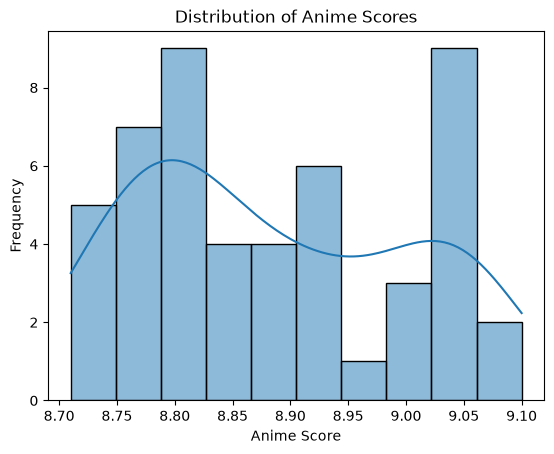

In [39]:
sns.histplot(data=df, x='Score', bins=10, kde=True)

plt.title('Distribution of Anime Scores')
plt.xlabel('Anime Score')
plt.ylabel('Frequency')

plt.show()

## Find the relationship between episodes and scores
**Does an anime with more episodes tend to have a higher score in your dataset?**

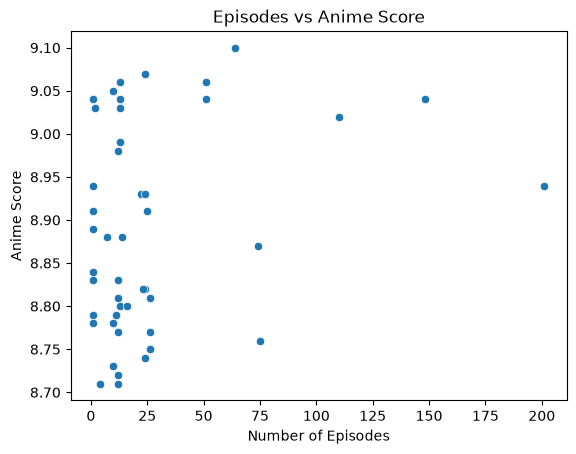

In [40]:
sns.scatterplot(data=data, x='Episode', y='Score')

plt.title('Episodes vs Anime Score')
plt.xlabel('Number of Episodes')
plt.ylabel('Anime Score')

plt.show()

**Visualize the relationship between airing duration and score**

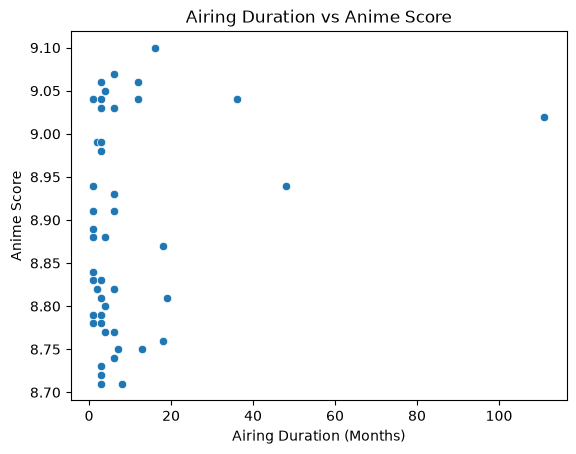

In [41]:
sns.scatterplot(data=data, x='Months', y='Score')

plt.title('Airing Duration vs Anime Score')
plt.xlabel('Airing Duration (Months)')
plt.ylabel('Anime Score')

plt.show()

**Visualize actual vs predicted scores**

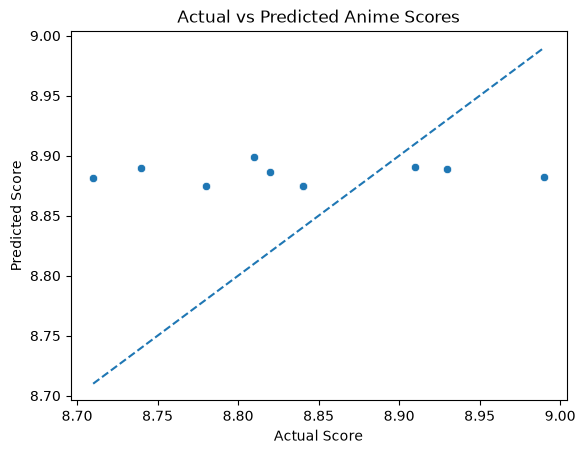

In [42]:
sns.scatterplot(x=y_test, y=predictions)

# Reference line for perfect predictions
min_score = min(y_test.min(), predictions.min())
max_score = max(y_test.max(), predictions.max())

plt.plot(
    [min_score, max_score],
    [min_score, max_score],
    linestyle='--'
)

plt.title('Actual vs Predicted Anime Scores')
plt.xlabel('Actual Score')
plt.ylabel('Predicted Score')

plt.show()

**BONUS: Visualize the correlation between your features**

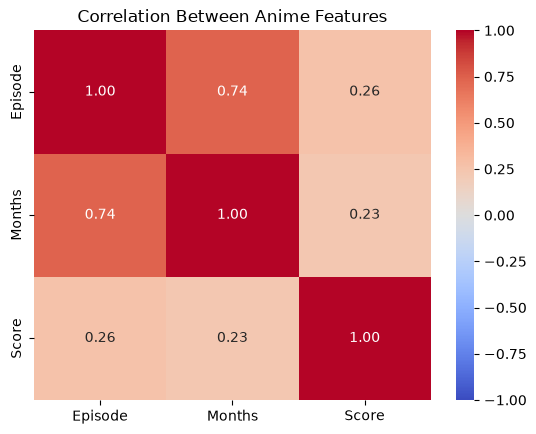

In [43]:
correlation = data[['Episode', 'Months', 'Score']].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)

plt.title('Correlation Between Anime Features')
plt.show()